In [ ]:
# Import neccessary libraries
import pandas as pd
import numpy as np

# For graph plot
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns

# For the DLNM model
import statsmodels.api as sm
from statsmodels.gam.api import GLMGam, BSplines, CyclicCubicSplines
from statsmodels.genmod.families.family import Tweedie
from statsmodels.genmod.families.links import log
from statsmodels.gam.smooth_basis import GenericSmoothers
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from pydlnm.utils import logknots

# Not used (DLNM model)
from pygam import GAM, LinearGAM, PoissonGAM, s
from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)
from statsmodels.tsa.seasonal import STL


In [223]:
# Import data and basic settings
df = pd.read_csv("data.csv")

df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB"]

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]

df["From"] = pd.to_datetime(df["From"])

In [235]:
def crossbasis_construct(dataframe, col_lst, max_lag, var_degree, var_df, lag_df):
    cb_list = []
    for col in col_lst:
        knots_var = np.quantile(dataframe[col].dropna(), [0.1, 0.75, 0.9])
        lag_knots = logknots([0, max_lag], nk=lag_df)

        tmp_cb = CrossBasis(dataframe[col].values, lag=max_lag, 
                                argvar={"fun": "bs", "degree": var_degree, "df": var_df}, 
                                arglag={"fun": "bs", "knots": lag_knots})
        cb_list.append(tmp_cb)

    X_exposure = np.concat(cb_list, axis=1)

    model_data = np.concat([dataframe.drop(columns=["From"]).to_numpy(), X_exposure], axis=1)
    model_data = pd.DataFrame(model_data)
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(tmp_cb.shape[1])]
    model_data.columns = [n for n in dataframe.columns if n!="From"] + exp_name_list
    model_data[exp_name_list] = model_data[exp_name_list].fillna(0)
    exp_names = " + ".join(exp_name_list)

    return model_data, exp_names

In [236]:
def smoothers_construct(dataframe, bs_dict, cs_dict):
    bs = BSplines(dataframe[bs_dict["name"]], df=[bs_dict["df"]], degree=[bs_dict["degree"]])
    cs = CyclicCubicSplines(dataframe[cs_dict["name"]], df=[cs_dict["df"]])
    combined_basis = bs.smoothers + cs.smoothers
    X_smooth = df[[bs_dict["name"]]+[cs_dict["name"]]].to_numpy()
    smoothers = GenericSmoothers(X_smooth, combined_basis)

    return smoothers

In [243]:
def NB_GAM_model(dataframe, tar_var, exp_names, smoothers): 
    formula = f"{tar_var} ~ {exp_names}"
    NegativeBinomial_gam_model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, family=sm.families.NegativeBinomial(alpha=0.5))
    result = NegativeBinomial_gam_model.fit()
    # result = NegativeBinomial_gam_model.fit_regularized(method="l1_slsqp", alpha=1.0)
        # no penalization for Negative Binomial

    return NegativeBinomial_gam_model, result.summary()

In [244]:
def Tweddie_GAM_model(dataframe, tar_var, exp_names, smoothers):
    formula = f"{tar_var} ~ {exp_names}"
    Tweddie_gam_model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, family=Tweedie(link=log(), var_power=1.5))
    result = Tweddie_gam_model.fit()

    return Tweddie_gam_model, result.summary()

In [245]:
model_data, exp_names = crossbasis_construct(df, mete_col, 4, 3, 4, 3)
smoothers = smoothers_construct(df, {"name": "Year", "degree": 3, "df": 25}, {"name": "Week", "df": 42})
model, result = NB_GAM_model(model_data, "H1", exp_names, smoothers)
print(result)


c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_result

                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                   877.47
Model Family:        NegativeBinomial   Df Model:                       374.53
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4215.8
Date:                Sun, 08 Nov 2026   Deviance:                       2274.6
Time:                        10:12:07   Pearson chi2:                 5.26e+03
No. Iterations:                  1000   Pseudo R-squ. (CS):             0.9994
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.7455      1

c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()


In [227]:
# Cross basis matrix construction for all Exposures 
cb_list = []
var_degree = 3
var_df = 4
lag_df = 3
max_lag = 4
for col in mete_col:
    knots_var = np.quantile(df[col].dropna(), [0.1, 0.75, 0.9])
    lag_knots = logknots([0, max_lag], nk=lag_df)

    tmp_cb = CrossBasis(df[col].values, lag=max_lag, 
                            argvar={"fun": "bs", "degree": var_degree, "df": var_df}, 
                            arglag={"fun": "bs", "knots": lag_knots})
    cb_list.append(tmp_cb)

X_exposure = np.concat(cb_list, axis=1)

model_data = np.concat([df.drop(columns=["From"]).to_numpy(), X_exposure], axis=1)
model_data = pd.DataFrame(model_data)
exp_name_list = [f"{col}_basis_{i}" for col in mete_col for i in range(tmp_cb.shape[1])]
model_data.columns = [n for n in df.columns if n!="From"] + exp_name_list
model_data[exp_name_list] = model_data[exp_name_list].fillna(0)
exp_names = " + ".join(exp_name_list)

In [229]:
# Construct the linear model use for DLNM 
formula = f"H1 ~ {exp_names}"
bs = BSplines(df["Year"], df=[25], degree=[3])
cs = CyclicCubicSplines(df["Week"], df=[42])
combined_basis = bs.smoothers + cs.smoothers
X_smooth = df[["Year", "Week"]].to_numpy()
smoothers = GenericSmoothers(X_smooth, combined_basis)

NegativeBinomial_gam_model = GLMGam.from_formula(formula, data=model_data, smoother=smoothers, family=sm.families.NegativeBinomial(alpha=0.5))
Tweddie_gam_model = GLMGam.from_formula(formula, data=model_data, smoother=smoothers, family=Tweedie(link=log(), var_power=1.5))

result = NegativeBinomial_gam_model.fit()
# result = NegativeBinomial_gam_model.fit_regularized(method="l1_slsqp", alpha=1.0)
    # no penalization for Negative Binomial
print(result.summary())

c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\genmod\families\links.py:1423: FutureWarning: The log link alias is deprecated. Use Log instead. The log link alias will be removed after the 0.15.0 release.
  _link_deprecation_warning("log", "Log")
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm

                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                   877.47
Model Family:        NegativeBinomial   Df Model:                       374.53
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4215.8
Date:                Sun, 08 Nov 2026   Deviance:                       2274.6
Time:                        09:53:13   Pearson chi2:                 5.26e+03
No. Iterations:                  1000   Pseudo R-squ. (CS):             0.9994
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.7455      1

In [ ]:
NegativeBinomial_gam_model.score()


TypeError: PenalizedMixin.score() missing 1 required positional argument: 'params'

c:\Users\yanss\OneDrive\Codes\4096_project_new\pydlnm\prediction.py:450: RuntimeWarning: overflow encountered in exp
  self.matRRhigh = np.exp(self.matfit + z_score * self.matse)
c:\Users\yanss\OneDrive\Codes\4096_project_new\pydlnm\prediction.py:454: RuntimeWarning: overflow encountered in exp
  self.allRRhigh = np.exp(self.allfit + z_score * self.allse)


temprange RR range: 0.000 to 8337.634


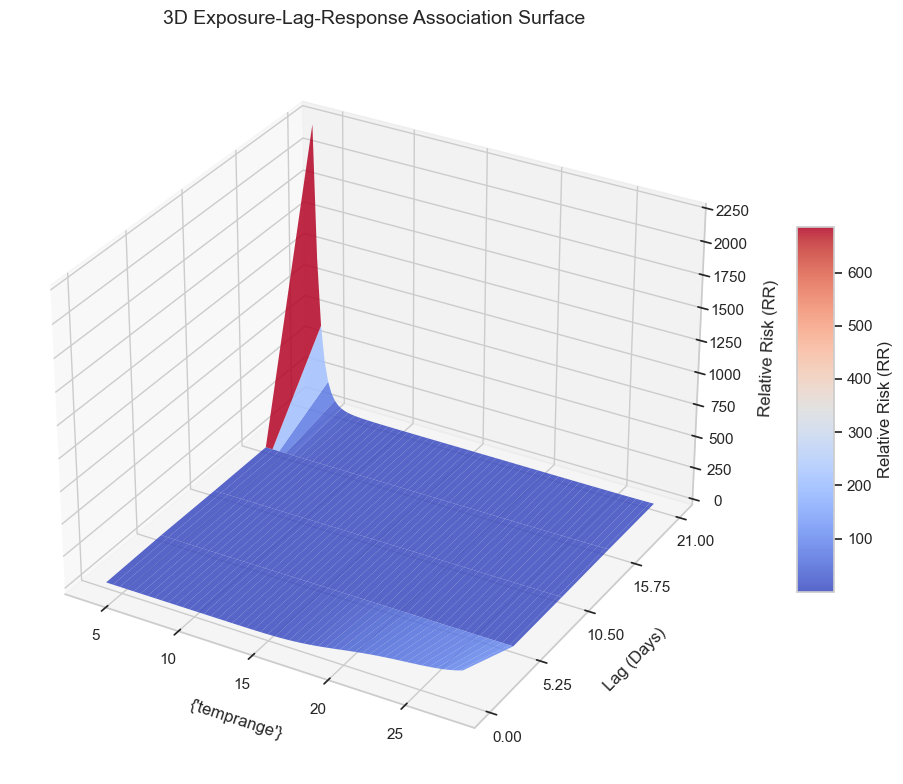

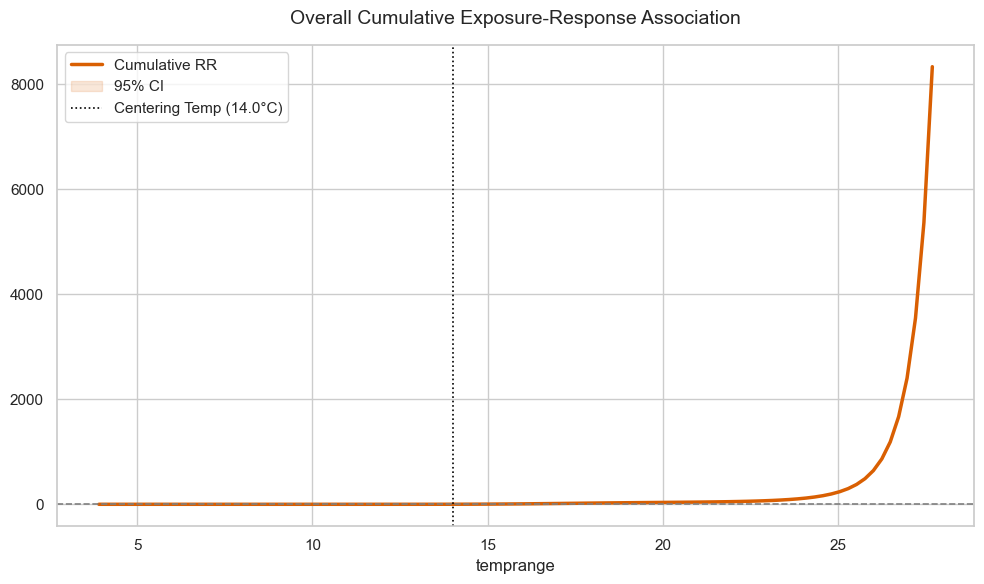

temp RR range: 0.000 to 315.208


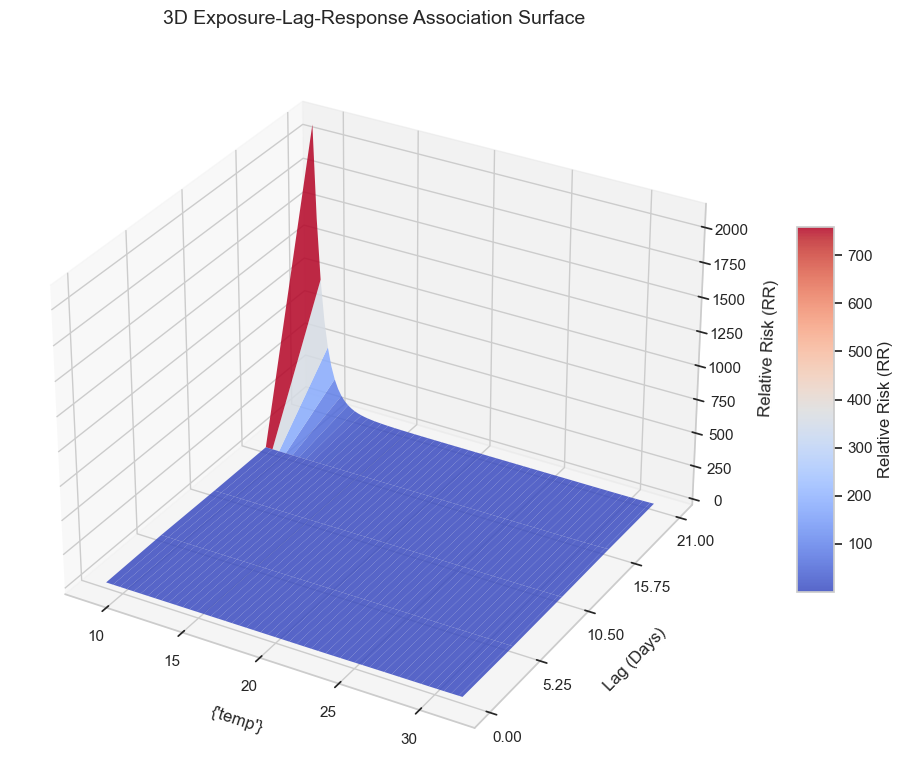

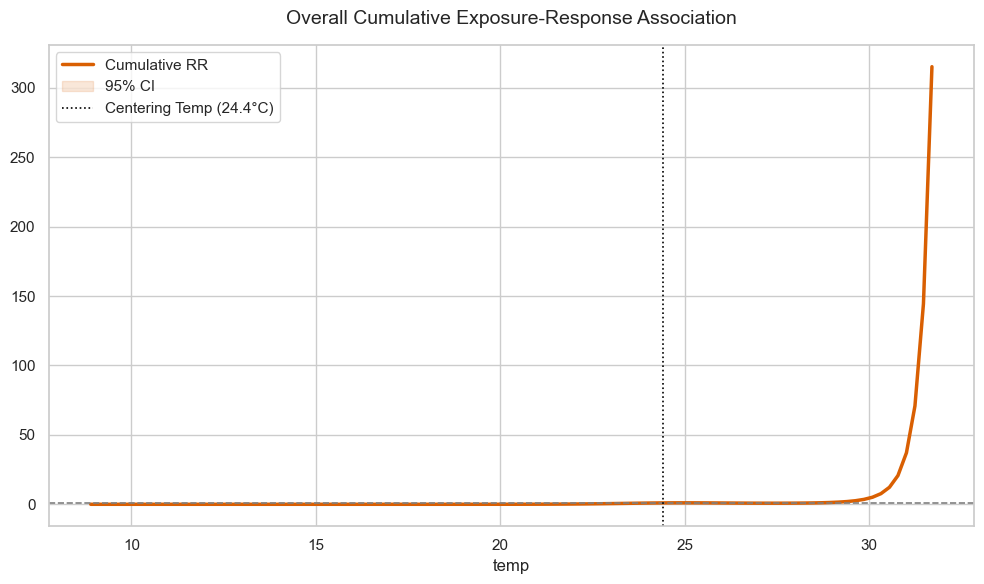

RH RR range: 0.000 to 295.321


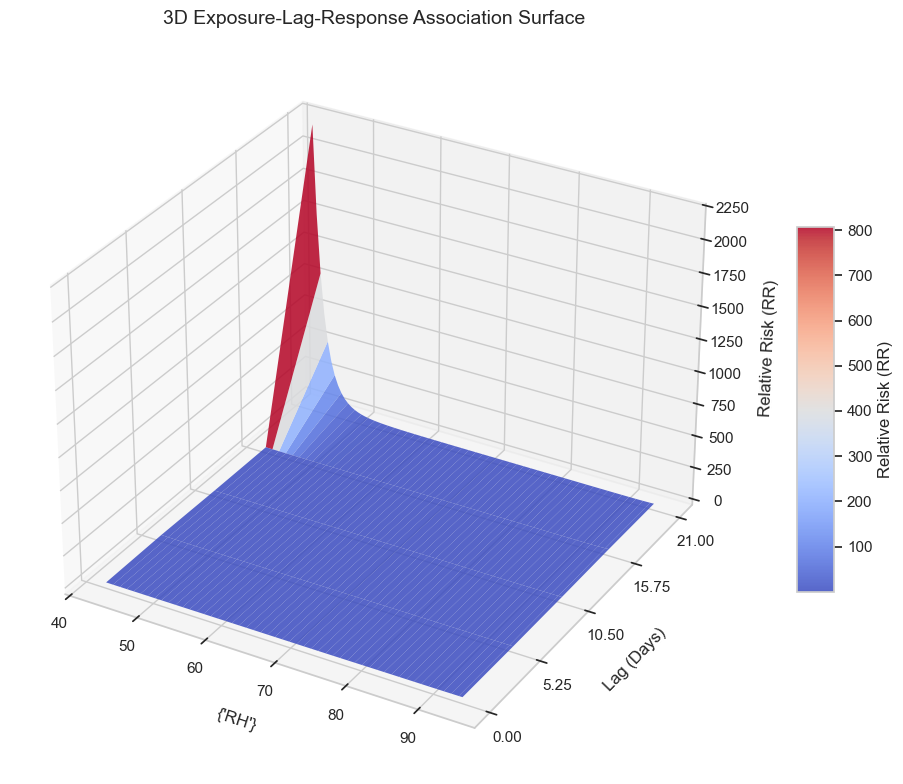

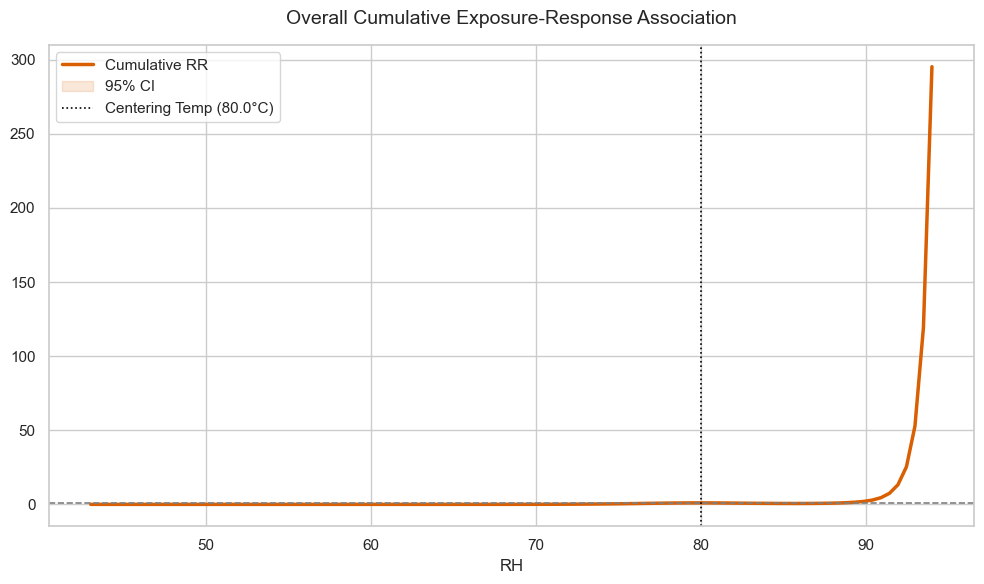

SR RR range: 0.000 to 1889.783


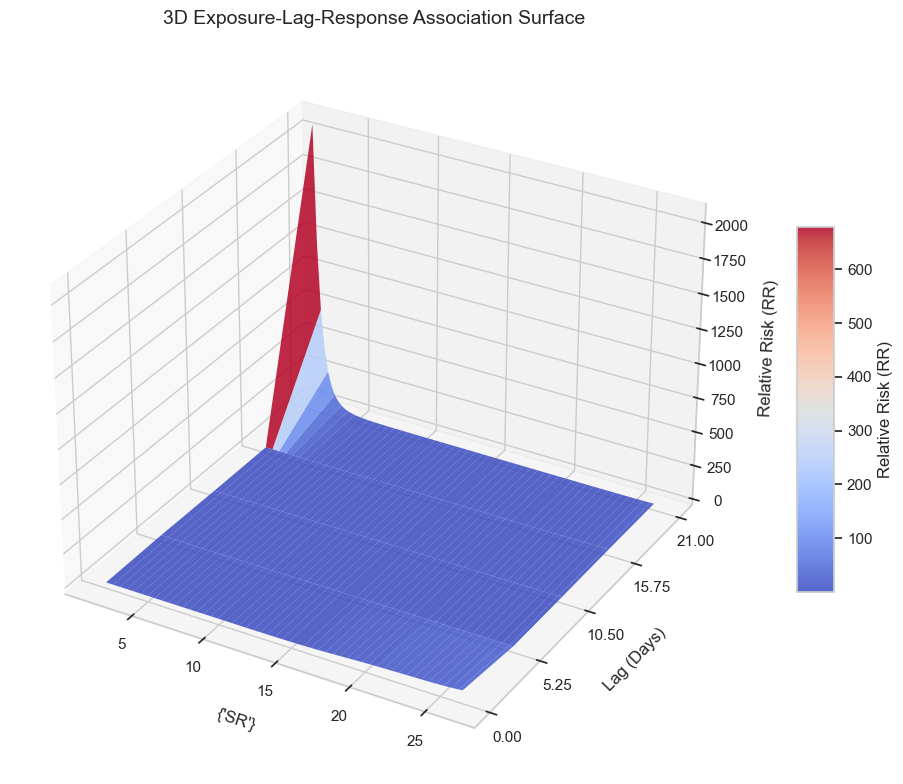

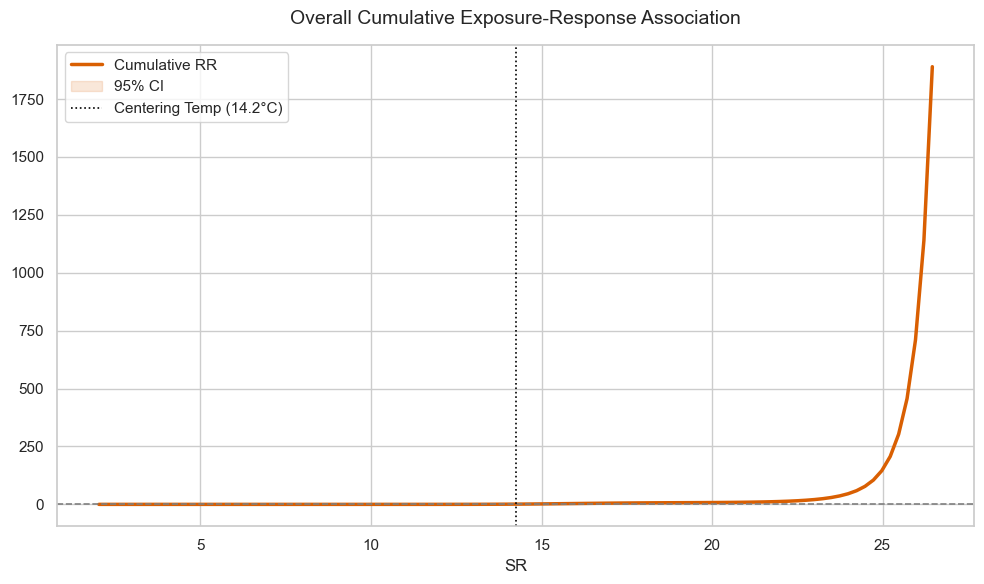

AP RR range: 0.000 to 1402.242


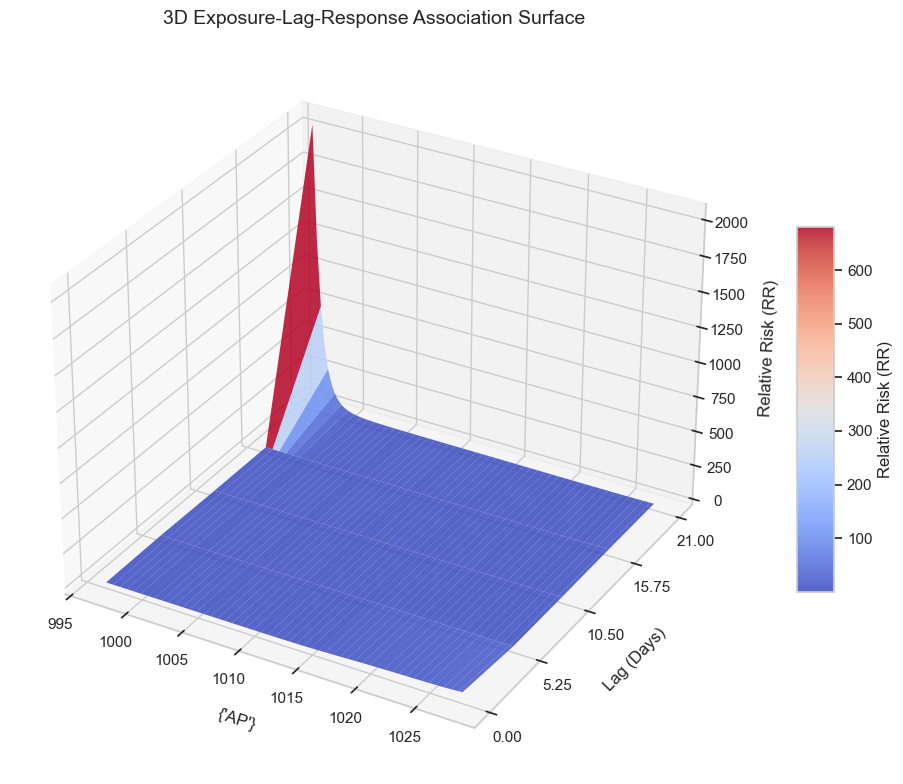

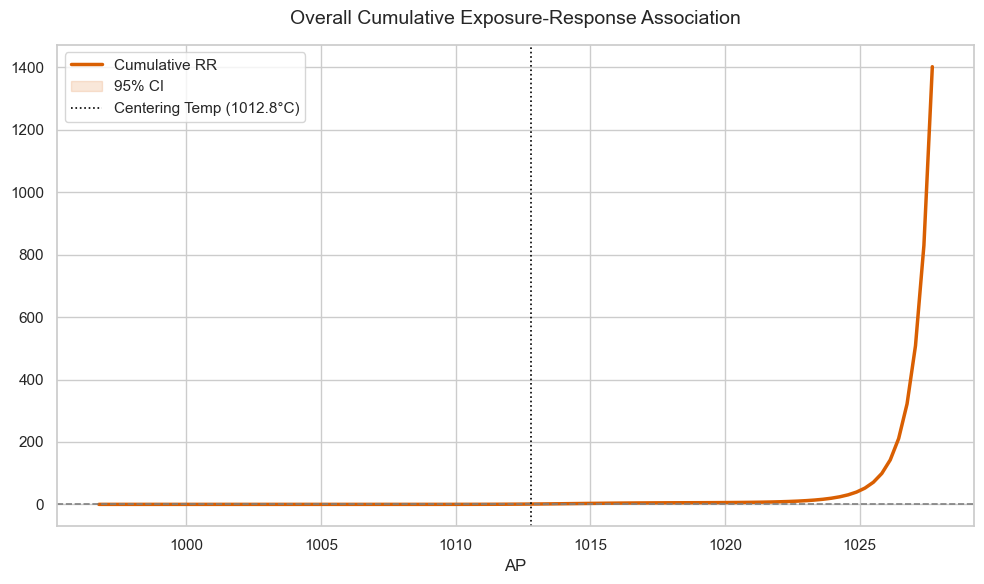

DPT RR range: 0.000 to 317.879


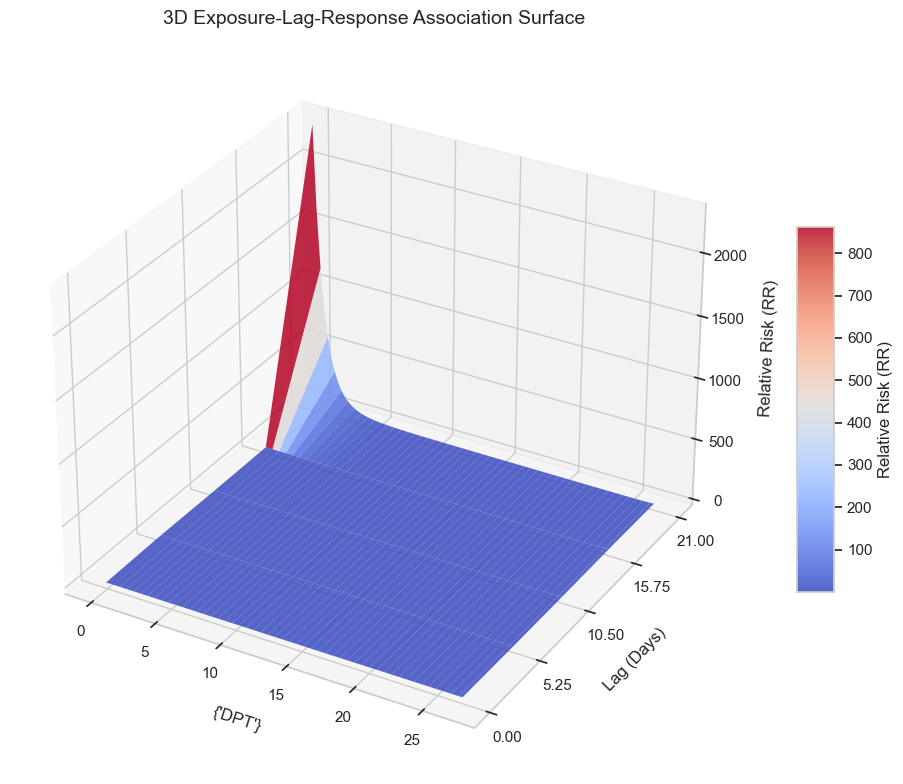

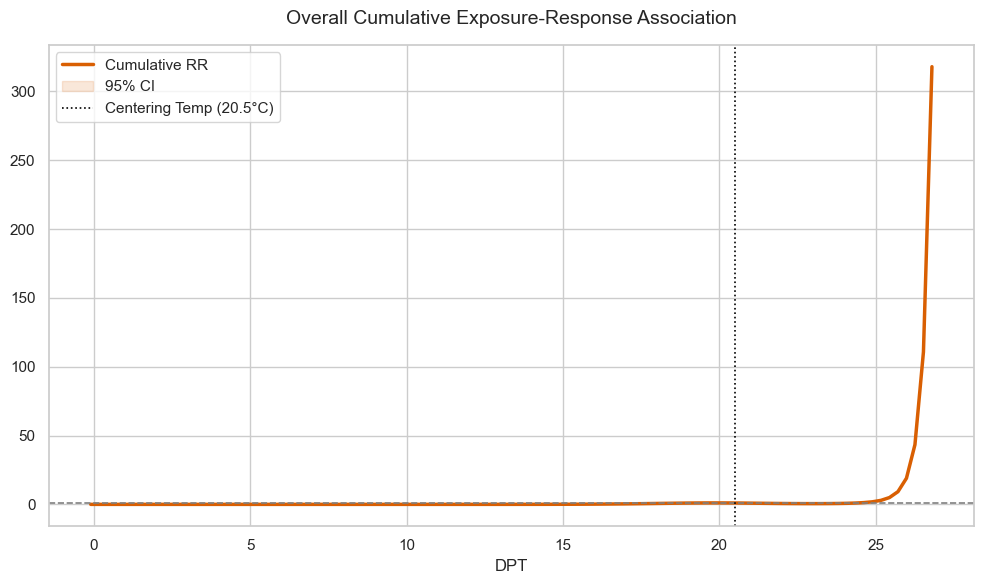

c:\Users\yanss\OneDrive\Codes\4096_project_new\pydlnm\prediction.py:452: RuntimeWarning: overflow encountered in exp
  self.allRRfit = np.exp(self.allfit)


WS RR range: 0.000 to inf


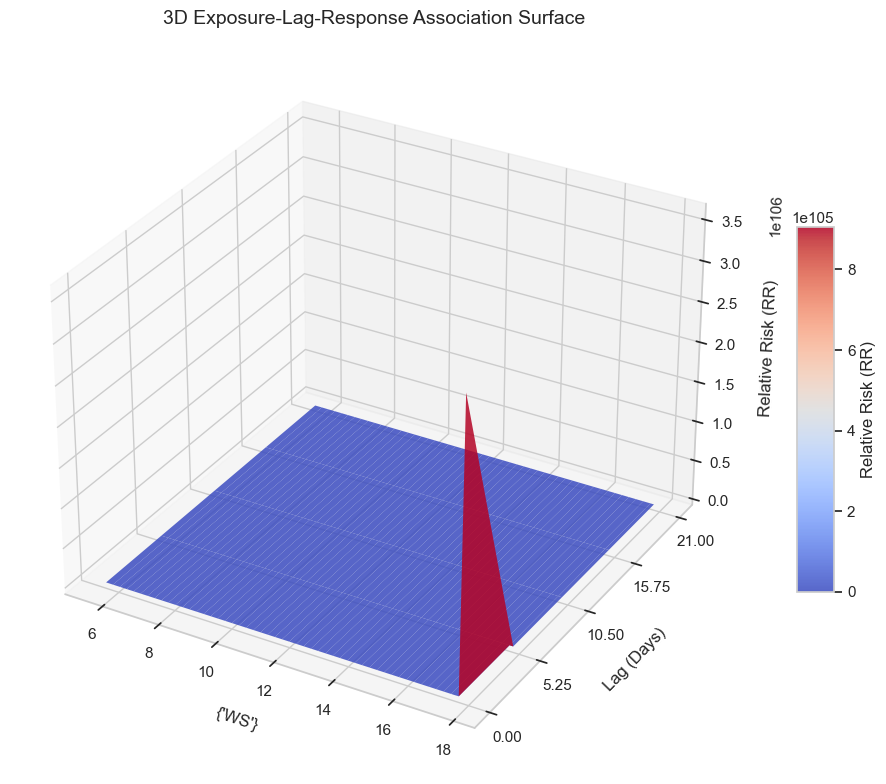

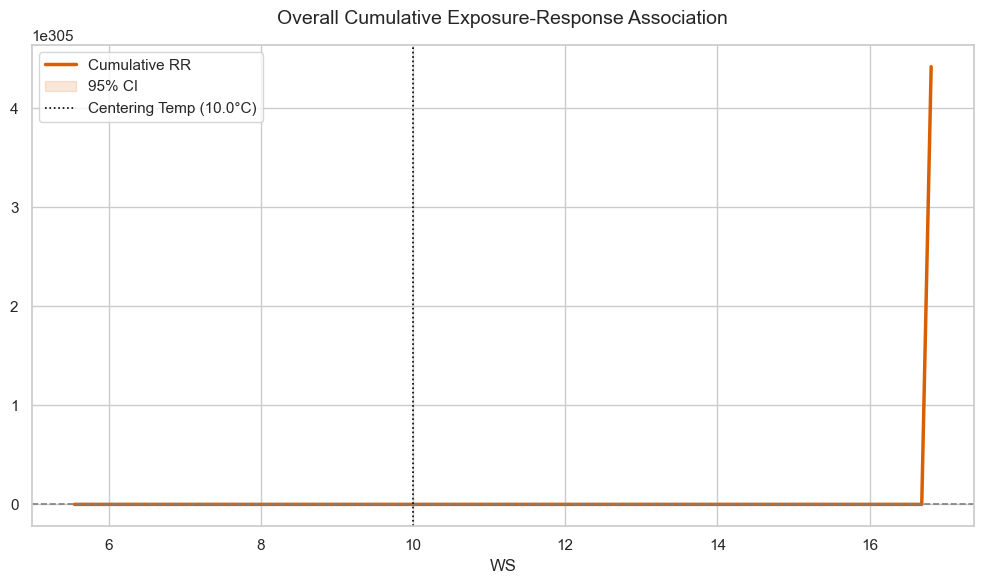

In [ ]:

for i in range(len(cb_list)):
    n_cb_cols = cb_list[i].shape[1]
    start_idx = 0
    end_idx = start_idx+n_cb_cols
    cb_coef = result.params.values[start_idx:end_idx]
    cb_vcov = result.cov_params().iloc[start_idx:end_idx, start_idx:end_idx]
    at = np.linspace(df[mete_col[i]].min(), df[mete_col[i]].max(), 100)
    cen = df[mete_col[i]].median()
    pred = crosspred(basis=cb_list[i], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)

    print(f"{mete_col[i]} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")


    # Verify if 3D matrix is available in your predictions
    if hasattr(pred, 'matRRfit'):
        # Z matrix shape is typically (len(pred.predvar), len(lags))
        # Let's align it so that Z is shaped as (len(pred.predvar), len(lags))
        n_rows, n_cols = pred.matRRfit.shape
        
        if n_rows == len(pred.predvar):
            Z = pred.matRRfit
        else:
            # If transposed, make sure rows correspond to temperature
            Z = pred.matRRfit.T
            n_rows, n_cols = Z.shape

        # 1. Dynamically build the coordinates based on actual matrix dimensions
        # This guarantees that the shape of your X, Y, and Z will match perfectly!
        temps_dimension = np.linspace(pred.predvar.min(), pred.predvar.max(), n_rows)
        lags_dimension = np.linspace(0, 21, n_cols)  # Maps your lag range (0 to 21) across the 5 columns

        # 2. Build the meshgrid matching (Temperatures x Lags)
        X, Y = np.meshgrid(temps_dimension, lags_dimension, indexing='ij')

        # 3. Plot the 3D Surface
        fig = plt.figure(figsize=(12, 8))
        ax = fig.add_subplot(111, projection='3d')
        
        # Plotting X, Y, and Z
        surf = ax.plot_surface(X, Y, Z, cmap=cm.coolwarm,
                            linewidth=0, antialiased=True, alpha=0.85)

        # Styling and Labels
        ax.set_xlabel({mete_col[i]}, labelpad=10)
        ax.set_ylabel('Lag (Days)', labelpad=10)
        ax.set_zlabel('Relative Risk (RR)', labelpad=10)
        ax.set_title('3D Exposure-Lag-Response Association Surface', fontsize=14, pad=15)
        
        # Customize the Lag tick labels to represent your 0-21 lag period
        ax.set_yticks(np.linspace(0, 21, n_cols))
        
        # Add Colorbar
        fig.colorbar(surf, shrink=0.5, aspect=10, label='Relative Risk (RR)')
        
        plt.tight_layout()
        plt.show()
    else:
        print("No 3D matrix (matRRfit) found in predictions.")



    sns.set_theme(style="whitegrid")

    plt.figure(figsize=(10, 6))

    # Plot the main cumulative RR curve
    plt.plot(pred.predvar, pred.allRRfit, color='#d95f02', lw=2.5, label='Cumulative RR')

    # Add 95% Confidence Interval as a shaded area
    if hasattr(pred, 'allRRlow') and hasattr(pred, 'allRRhigh'):
        plt.fill_between(pred.predvar, pred.allRRlow, pred.allRRhigh, 
                        color='#d95f02', alpha=0.15, label='95% CI')

    # Add reference line at RR = 1.0 (null association)
    plt.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.2)

    plt.axvline(x=cen, color='black', linestyle=':', linewidth=1.2, label=f'Centering Temp ({cen:.1f}°C)')
    plt.title('Overall Cumulative Exposure-Response Association', fontsize=14, pad=15)
    plt.xlabel(mete_col[i], fontsize=12)
    plt.legend(loc='best', frameon=True)

    plt.tight_layout()
    plt.show()


In [20]:
res_bs = Tweddie_gam_model.fit()
print(res_bs.summary())

c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_result

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  AandB   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                  1114.38
Model Family:                 Tweedie   Df Model:                       137.62
Link Function:                    log   Scale:                          15.765
Method:                         PIRLS   Log-Likelihood:                -7638.0
Date:                Sat, 07 Nov 2026   Deviance:                       15318.
Time:                        14:56:01   Pearson chi2:                 1.76e+04
No. Iterations:                    16   Pseudo R-squ. (CS):             0.6533
Covariance Type:            nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.8827      0.67

c:\Users\yanss\anaconda3\Lib\site-packages\statsmodels\gam\generalized_additive_model.py:1223: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = lm.WLS(aug_y, aug_x, aug_weights).fit()
